# Auxotrophies and minimal medium

In [1]:
import reframed
import pandas as pd
import numpy as np
from os import listdir
import warnings
import seaborn as sns
from collections import OrderedDict
import json

In [2]:
import sys

sys.path.append("../functions/")
from minimal_medium import make_minimal_media_df

In [3]:
%load_ext autoreload
%autoreload 2

**Set gurobi as default solver**

In [4]:
reframed.set_default_solver("gurobi")

**Load models**

*E. coli mutants (all 38)*

In [5]:
models_ecoli = {}
with warnings.catch_warnings():
    warnings.filterwarnings('ignore')
    for path in listdir("../models/Guillen2021/strains/"):
        if not path.endswith(".xml"): continue
        models_ecoli[path.split("_")[1][:-4]] = reframed.load_cbmodel("../models/Guillen2021/strains/"+path)

*Gut microbiome members*

In [6]:
models_gut = {}
with warnings.catch_warnings():
    warnings.filterwarnings('ignore')
    for path in listdir("../models/Venturelli2018/species_used_noO2/"):
        models_gut[path[:-4]] = reframed.load_cbmodel("../models/Venturelli2018/species_used_noO2/"+path,exchange_detection="R_EX_(?!biomass__40__e__41__)")


**Load media**

*For E. coli mutants (LB medium to see auxotrophies)*

In [7]:
media_db = pd.read_csv("https://raw.githubusercontent.com/cdanielmachado/carveme/refs/heads/master/carveme/data/input/media_db.tsv",sep="\t")
compounds = list(media_db[media_db.medium=="LB"].compound.values)
compounds.append("btn") # biot members are auxotrophic to biotin which was not in LB-medium. 
compounds.append("mmet") # metE and metH double mutant has been shown to be dependent on mmet (S-Methylmethionine). metH is missing in the model!
compounds.append("26dap__M") # meso-DAP. Essential part of cell wall in gram-negative bacteria...
env_ecoli = reframed.Environment.from_compounds(compounds)

*For gut microbiome members*

In [8]:
media_db_gut = pd.read_csv("../data/Venturelli2018/generated/media_db_lb_extend.tsv",sep="\t")
reactions = media_db_gut[media_db_gut.medium=="LB_extend"].compound.values
reactions = [rxn.replace("91","40").replace("93","41") for rxn in reactions]

env_gut = reframed.Environment.from_reactions(reactions)

**Load other data**

In [9]:
relative_abundance_ecoli = pd.read_csv("../data/Guillen2021/relative_abundance.csv",index_col=0)
relative_abundance_ecoli.index = relative_abundance_ecoli.index.map(lambda x:x if x!="yhhK" else "panZ")

In [10]:
gene_id2name = pd.read_csv("../data/Guillen2021/generated/gene_id2name.tsv",sep="\t")

**Translation dicts**

In [11]:
mets_id_ag = []
mets_id_bigg = []
ex_rxns_ag = []
for model in models_gut.values():
    for rxn in model.get_exchange_reactions():
        if "R_EX_" not in rxn:
            continue
        met_id_ag = model.reactions[rxn].get_substrates()[0]
        mets_id_ag.append(met_id_ag)
        met_id_bigg = model.metabolites[met_id_ag].metadata["XMLAnnotation"].split("bigg.metabolite/")[1].split("\"")[0]
        mets_id_bigg.append(met_id_bigg)
        ex_rxns_ag.append(rxn)
    
met2ex = dict(zip(mets_id_bigg,ex_rxns_ag))

### Find minimal medium

In [12]:
minimal_media_df_ecoli = make_minimal_media_df(models_ecoli,env_ecoli)

Set parameter Username
Academic license - for non-commercial use only - expires 2026-03-27
mutant_trpA: Objective: 1014.6551969265449
Status: Unknown

mutant_pyrD: Objective: 849.5093969265449
Status: Unknown

mutant_panZ: Objective: 898.5156440111385
Status: Unknown

mutant_trpE: Objective: 1014.6551969265449
Status: Unknown

mutant_pheA: Objective: 1014.698096926545
Status: Unknown

mutant_pdxA: Objective: 1016.670996926545
Status: Unknown

mutant_leuB: Objective: 980.6817969265448
Status: Unknown

mutant_bioD: Objective: 898.5154974131492
Status: Unknown

mutant_argB: Objective: 968.631496926545
Status: Unknown

mutant_tyrA: Objective: 1030.697496926545
Status: Unknown

mutant_bioF: Objective: 898.5154974131492
Status: Unknown

mutant_argA: Objective: 968.631496926545
Status: Unknown

mutant_bioC: Objective: 898.5154974131492
Status: Unknown

mutant_ptsI: Objective: 849.5093969265449
Status: Unknown

mutant_bioA: Objective: 898.5154974131492
Status: Unknown

mutant_icd: Objective: 9

In [13]:
minimal_media_df_gut = make_minimal_media_df(models_gut,env_gut)

M_Bacteroides_uniformis_ATCC_8492: Objective: 983.064
Status: Unknown

M_Bacteroides_vulgatus_ATCC_8482: Objective: 3737.6828909917567
Status: Unknown

M_Collinsella_aerofaciens_ATCC_25986: Objective: 3020.0449
Status: Unknown

M_Faecalibacterium_prausnitzii_A2_165: Objective: 3133.0438041399198
Status: Unknown

M_Eggerthella_lenta_DSM_2243: Objective: 5528.728290991758
Status: Unknown

M_Prevotella_copri_CB7_DSM_18205: Objective: 967.7866999999999
Status: Unknown

M_Clostridium_hiranonis_TO_931_DSM_13275: Objective: 3798.7868
Status: Unknown

M_Eubacterium_rectale_ATCC_33656: Objective: 1917.749804141158
Status: Unknown

M_Desulfovibrio_piger_ATCC_29098: Objective: 1332.0876263251819
Status: Unknown

M_Bacteroides_ovatus_ATCC_8483: Objective: 963.0754224328543
Status: Unknown

M_Bacteroides_thetaiotaomicron_VPI_5482: Objective: 2602.109364007905
Status: Unknown

M_Blautia_hydrogenotrophica_DSM_10507: Objective: 2574.3438000000006
Status: Unknown



In [14]:
minimal_media_df_gut.to_csv("../output/Venturelli2018/minimal_media.tsv",sep="\t")

minimal_media_df_ecoli.to_csv("../output/Guillen2021/minimal_media.tsv",sep="\t")

### Plot solutions

**Remove results for less interesting compounds**: *compounds that few members have auxotrophy for/compounds all members have auxotrophy for, and minerals etc (from M9 medium)*

In [15]:
m9_mets = media_db[media_db.medium=="M9"].compound.values
m9_rxns = ["R_EX_"+met+"_e" for met in m9_mets]

m9_rxns_gut = ["R_EX_"+met+"__40__e__41__" for met in m9_mets]

In [16]:
minimal_media_df_ecoli_plot = minimal_media_df_ecoli.loc[(minimal_media_df_ecoli.sum(axis=1)<750*minimal_media_df_ecoli.shape[1]) & (minimal_media_df_ecoli.sum(axis=1)>=900)]
minimal_media_df_ecoli_plot = minimal_media_df_ecoli_plot[~minimal_media_df_ecoli_plot.index.isin(m9_rxns)]

minimal_media_df_gut_plot = minimal_media_df_gut.loc[(minimal_media_df_gut.sum(axis=1)<750*minimal_media_df_gut.shape[1]) & (minimal_media_df_gut.sum(axis=1)>=900)]
minimal_media_df_gut_plot = minimal_media_df_gut_plot[~minimal_media_df_gut_plot.index.isin(m9_rxns_gut)]


**Define color palette**

In [17]:
bigg_met2chebi_class = pd.read_csv("../../../GEMs_from_MAGs/output/met_chebi_class.tsv",sep="\t",index_col=0)

met2chebi = bigg_met2chebi_class["self defined super class"].to_dict()
met2chebi = {key[2:-2]:value for key,value in met2chebi.items()}

agoraEx2chebi = {met2ex[key]: value for key, value in met2chebi.items() if key in met2ex.keys()}

for value in minimal_media_df_gut.index:
    if value not in agoraEx2chebi.keys():
        agoraEx2chebi[value]="undefined"

biggEx2chebi = {"R_EX_"+met+"_e":super_class for met,super_class in met2chebi.items() if "R_EX_"+met+"_e" in minimal_media_df_ecoli_plot.index}
for value in minimal_media_df_ecoli_plot.index:
    if value not in biggEx2chebi.keys():
        biggEx2chebi[value]="undefined"


pallete = sns.color_palette("tab20b",20)
pallete.reverse()
pallete2 = sns.color_palette("tab20c",20)
pallete2.reverse()
pallete.extend([pallete2[-3],pallete2[-1]])


super_classes = list(set(agoraEx2chebi.values()))+list(set(biggEx2chebi.values()))
pallete_dict = OrderedDict(zip(super_classes,pallete))
pallete_series_agora = pd.Series({key:pallete_dict[value] for key,value in agoraEx2chebi.items()} )
pallete_series_bigg = pd.Series({key:pallete_dict[value] for key,value in biggEx2chebi.items()} )


#### Members of E.coli mutants

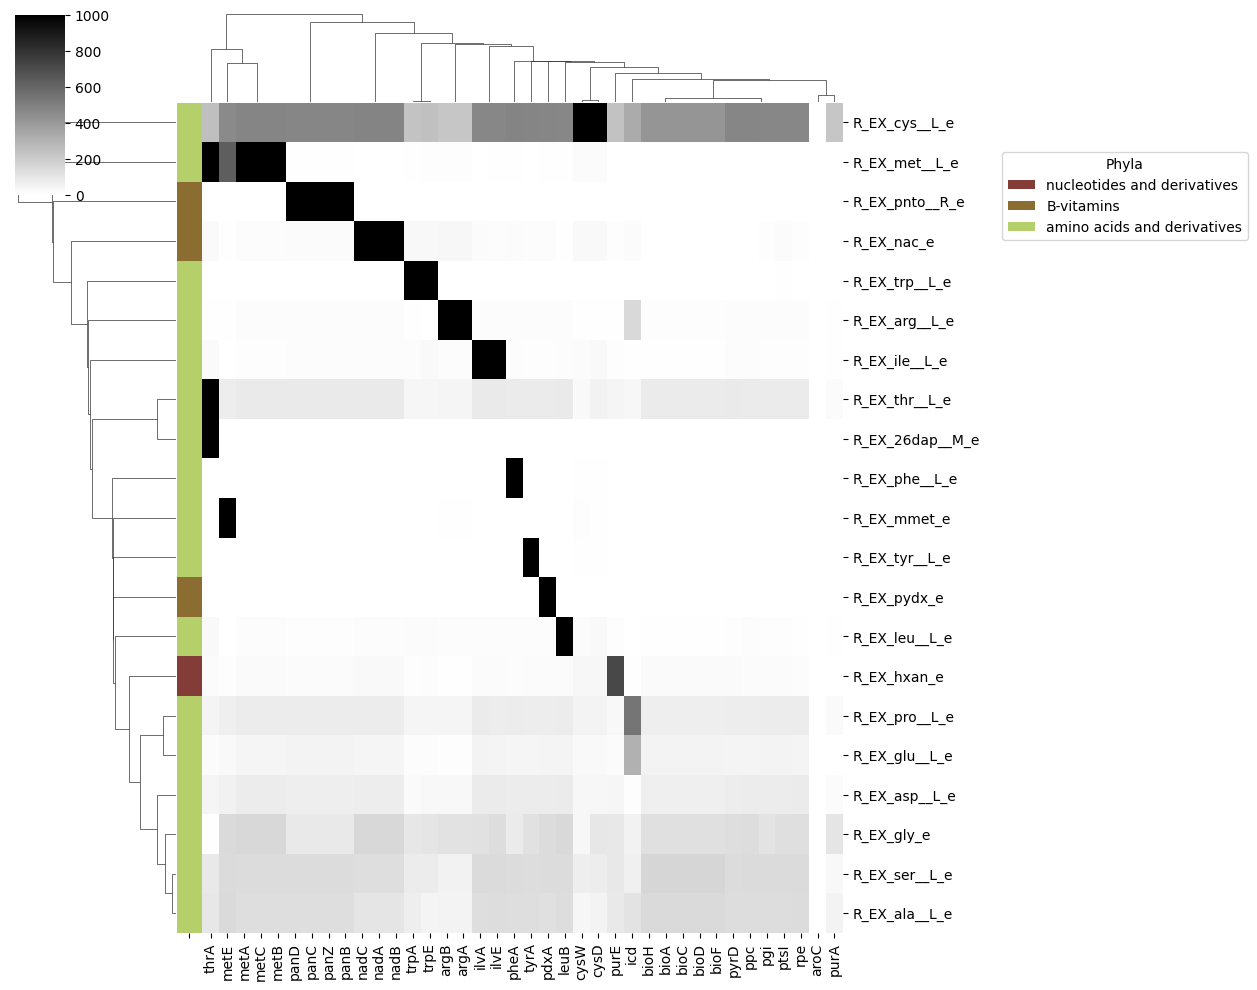

In [18]:
from matplotlib.pyplot import gcf

g = sns.clustermap(minimal_media_df_ecoli_plot,
                   cmap="binary",
                   method="ward",
                   vmin=0,
                   fmt="d",
                   dendrogram_ratio=(0.2, 0.1),
                   row_colors=pallete_series_bigg,
                   xticklabels=1)

relevant_classes = list(set([biggEx2chebi[key] for key in minimal_media_df_ecoli_plot.index]))

for label in relevant_classes:
    g.ax_col_dendrogram.bar(0, 0, color=pallete_dict[label], label=label, linewidth=0)
l1 = g.ax_col_dendrogram.legend(title='Phyla',ncol=1, bbox_to_anchor=(1.0, 0.85), loc='upper left',bbox_transform=gcf().transFigure)

**Find experimental results for top 7 members**

In [19]:
RA_ecoli_mean = relative_abundance_ecoli.T.mean().sort_values(ascending=False)
RA_ecoli_mean[RA_ecoli_mean>0.01]

icd     0.287848
panZ    0.276678
bioH    0.211130
bioF    0.098526
cysW    0.062219
bioC    0.020200
panD    0.015948
dtype: float64

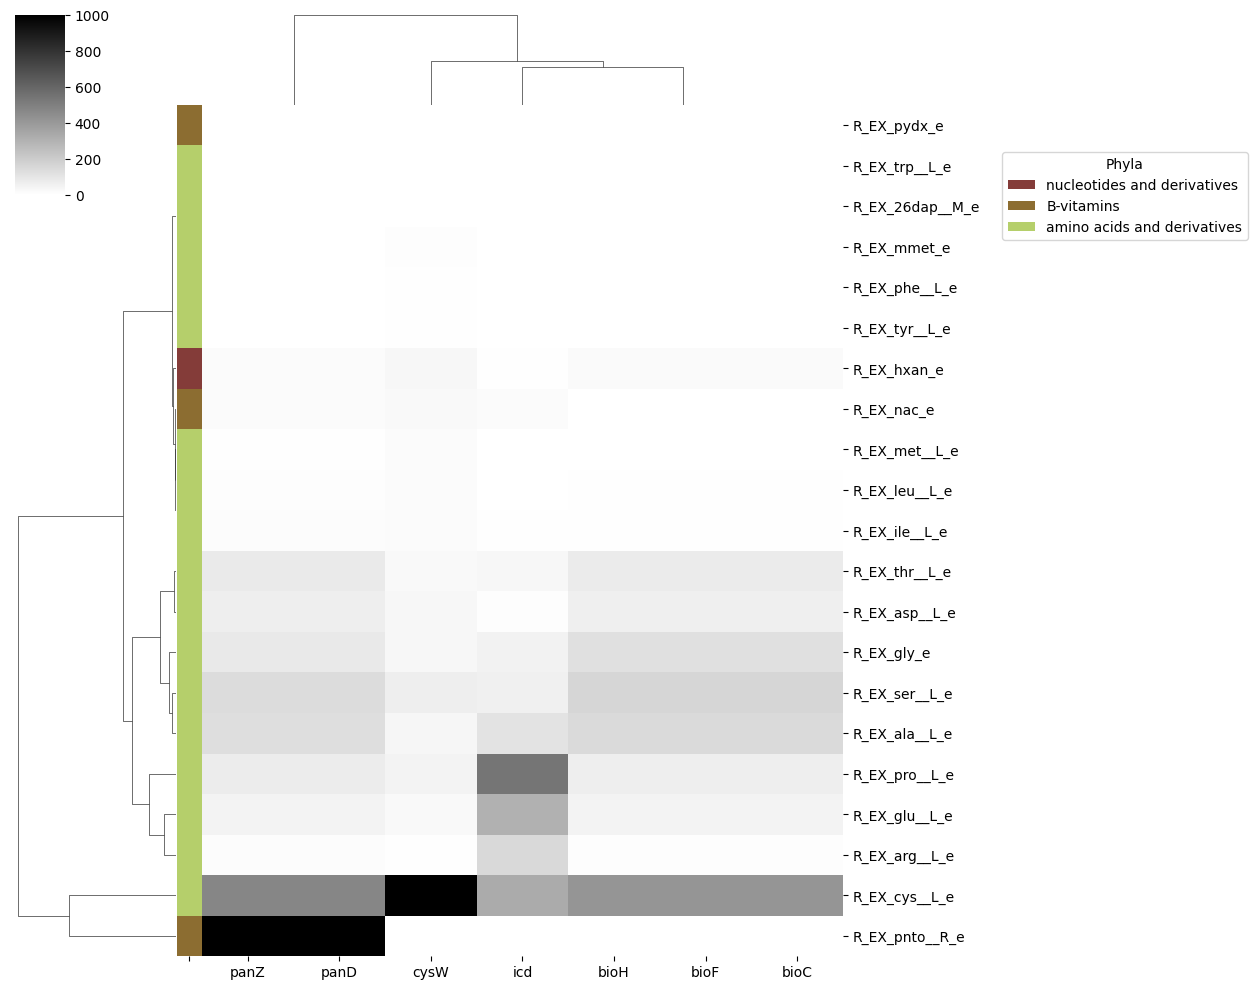

In [20]:
relevant_ecoli_mutants = RA_ecoli_mean[RA_ecoli_mean>0.01].index
minimal_media_df_ecoli_plot2 = minimal_media_df_ecoli_plot.loc[:,minimal_media_df_ecoli_plot.columns.isin(relevant_ecoli_mutants)]

g = sns.clustermap(minimal_media_df_ecoli_plot2,
                   cmap="binary",
                   method="ward",
                   vmin=0,
                   fmt="d",
                   dendrogram_ratio=(0.2, 0.1),
                   row_colors=pallete_series_bigg,
                   xticklabels=1)

relevant_classes = list(set([biggEx2chebi[key] for key in minimal_media_df_ecoli_plot2.index]))

for label in relevant_classes:
    g.ax_col_dendrogram.bar(0, 0, color=pallete_dict[label], label=label, linewidth=0)
l1 = g.ax_col_dendrogram.legend(title='Phyla',ncol=1, bbox_to_anchor=(1.0, 0.85), loc='upper left',bbox_transform=gcf().transFigure)

<span style="color:red"> NB! bio(*) strains are auxotrophic to biotin (btn) - confirmed by removing from media.  I don't understand why it doesn't show...

In [21]:
bio_members = ["bioH","bioF","bioC","panZ"] #panZ for control


In [22]:
env_ecoli_no_btn = env_ecoli.copy()
env_ecoli_no_btn.pop("R_EX_btn_e")


(-10.0, inf)

In [23]:
for mutant in bio_members:
    model = models_ecoli[mutant].copy()
    env_ecoli_no_btn.apply(model,inplace=True,exclusive=True,warning=False)
    
    sol = reframed.FBA(model)
    print(f"{mutant}: {sol.fobj}")

bioH: -0.0
bioF: -0.0
bioC: -0.0
panZ: 3.4324385547427054


#### Members of gut microbiome

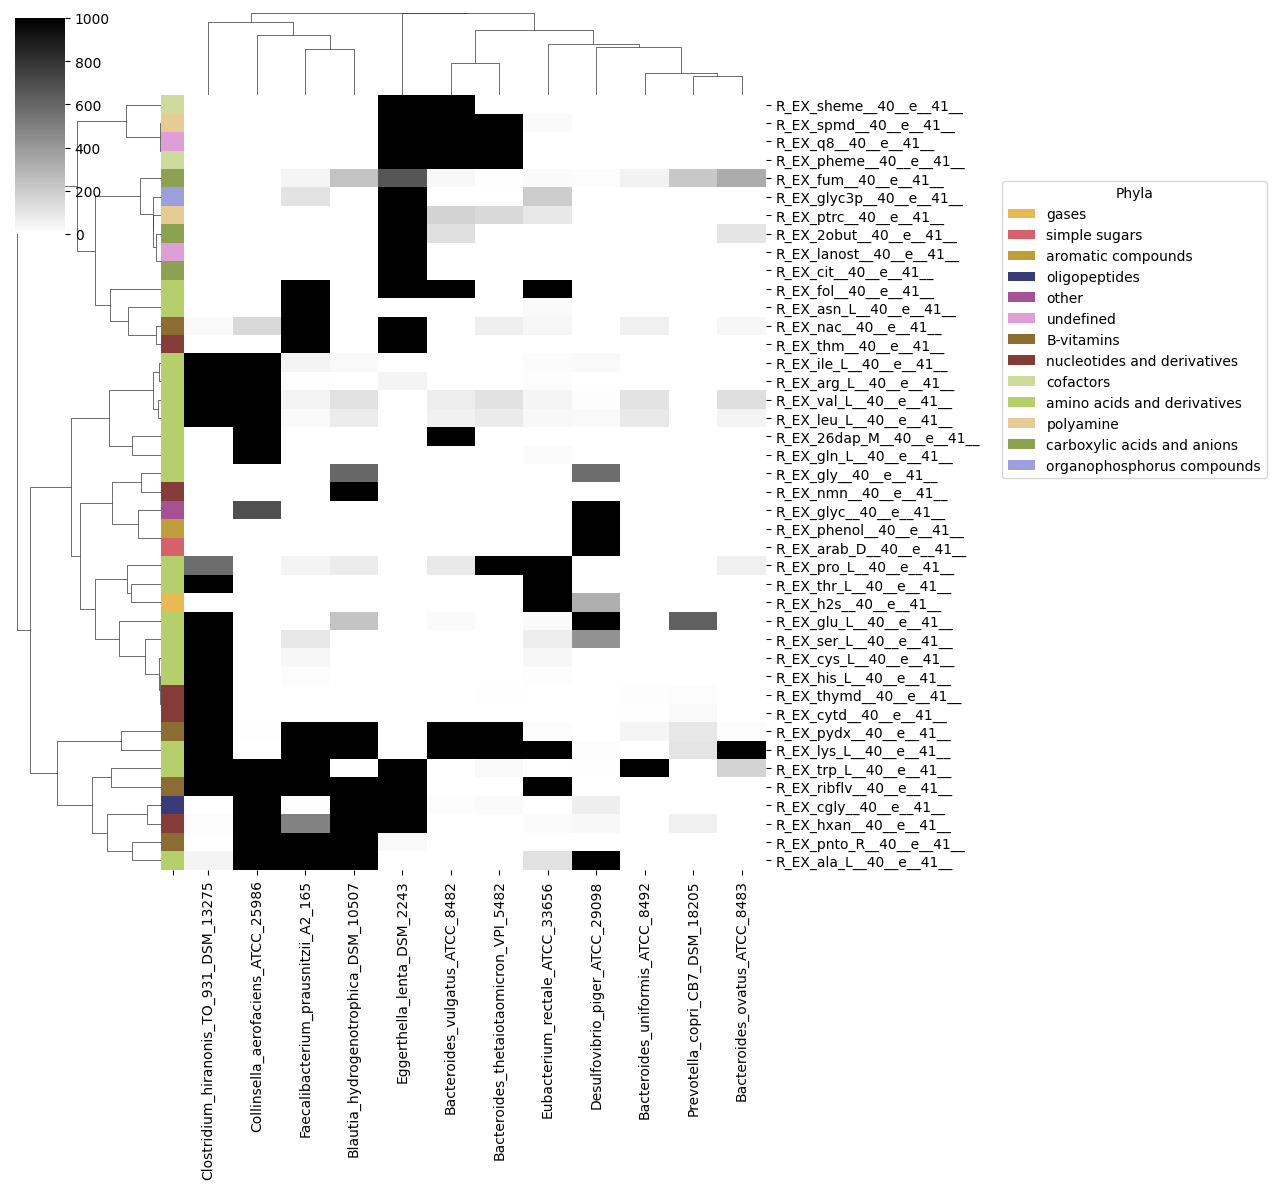

In [24]:
g = sns.clustermap(minimal_media_df_gut_plot,
                   figsize=(10,12),
                   cmap="binary",
                   method="ward",
                   vmin=0,
                   fmt="d",
                   dendrogram_ratio=(0.2, 0.1),
                   row_colors=pallete_series_agora,
                   xticklabels=1)

relevant_classes = list(set([agoraEx2chebi[key] for key in minimal_media_df_gut_plot.index]))

for label in relevant_classes:
    g.ax_col_dendrogram.bar(0, 0, color=pallete_dict[label], label=label, linewidth=0)
l1 = g.ax_col_dendrogram.legend(title='Phyla',ncol=1, bbox_to_anchor=(1.0, 0.85), loc='upper left',bbox_transform=gcf().transFigure)